# 01 — Analyse exploratoire de la Ligue 1 ivoirienne (2016 → 2026)

Données : export de PostgreSQL (`python -m src.restitution.export`), fichiers `app/data/*.parquet`. Questions : quelle est la répartition des résultats ? Combien de buts ? L'avantage du terrain existe-t-il ? Le championnat est-il dominé par un club ? Qu'est-ce que cela implique pour la prédiction ?

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
DATA = RACINE / "app" / "data"
RES = RACINE / "docs" / "resultats"
ORANGE, VERT, GRIS = "#E07000", "#006B45", "#9A9A94"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E8EB", "axes.axisbelow": True})

## 1. Volume et qualité des données

In [2]:
matchs = pd.read_parquet(DATA / "matchs.parquet")
print(matchs["statut"].value_counts())
joues = matchs[matchs["statut"] == "joue"].copy()
joues.groupby("saison").agg(matchs=("id_match", "size"), clubs=("dom", "nunique"),
                            premiere_date=("date_match", "min"),
                            derniere_date=("date_match", "max"))

statut
joue          1934
a_jouer        227
abandonne        6
tapis_vert       3
Name: count, dtype: int64


,matchs,clubs,premiere_date,derniere_date
saison,,,,
2016-2017,182,14,2016-11-19,2017-07-03
2017-2018,182,14,2017-10-14,2018-06-03
2018-2019,181,14,2018-09-07,2019-05-05
2019-2020,140,14,2019-08-17,2020-03-08
2020-2021,95,14,2021-03-27,2021-06-26
2021-2022,182,14,2021-11-20,2022-06-30
2022-2023,240,16,2022-09-10,2023-06-11
2023-2024,239,16,2023-10-07,2024-06-01
2024-2025,240,16,2024-09-20,2025-05-19


Dix saisons complètes (sauf 2019-20, arrêtée par le Covid, et 2020-21, jouée en deux poules puis un play-off). La saison 2026-27 vient de commencer.

## 2. Répartition des résultats

In [3]:
rep = joues["resultat"].value_counts(normalize=True).rename({"D": "domicile", "N": "nul", "E": "extérieur"})
print((rep * 100).round(1))
pd.read_parquet(DATA / "resultats_saison.parquet")

resultat
domicile     36.0
extérieur    33.7
nul          30.3
Name: proportion, dtype: float64


,saison,matchs,pct_domicile,pct_nul,pct_exterieur,buts_par_match,pct_un_but_ou_moins
0,2016-2017,182,35.7,34.1,30.2,1.80,46.7
1,2017-2018,182,39.0,35.2,25.8,1.99,42.9
2,2018-2019,181,41.4,27.1,31.5,2.15,35.4
3,2019-2020,140,33.6,30.7,35.7,2.22,33.6
4,2020-2021,95,33.7,34.7,31.6,1.91,45.3
5,2021-2022,182,36.8,26.4,36.8,2.15,38.5
6,2022-2023,240,38.8,31.3,30.0,2.10,37.1
7,2023-2024,239,37.7,28.9,33.5,2.15,38.9
8,2024-2025,240,30.0,30.8,39.2,2.14,35.8
9,2025-2026,240,33.8,26.7,39.6,2.00,44.2


**Constat clé** : environ **un match sur trois est un nul**, contre ~25 % en Europe, et les victoires à domicile ne représentent que ~37 % des matchs. Une prédiction en 3 classes est donc intrinsèquement difficile : l'issue la plus probable dépasse rarement 50 %.

## 3. Buts et scores

Buts par match : 2.06


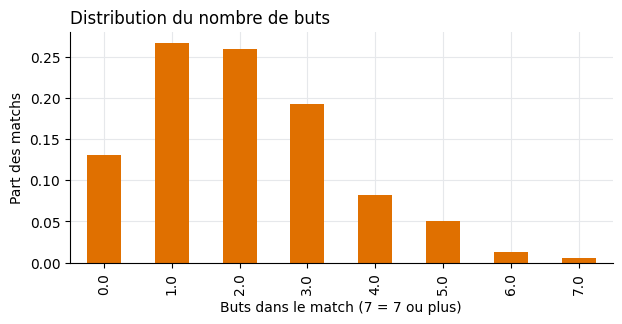

,score,matchs,pct,pct_cumule
0,1-1,274,14.2,14.2
1,1-0,270,14.0,28.1
2,0-0,252,13.0,41.2
3,0-1,246,12.7,53.9
4,1-2,160,8.3,62.2
5,2-0,128,6.6,68.8
6,2-1,128,6.6,75.4
7,0-2,99,5.1,80.5
8,2-2,53,2.7,83.2
9,3-0,48,2.5,85.7


In [4]:
joues["total"] = joues["buts_dom"] + joues["buts_ext"]
print("Buts par match :", round(joues["total"].mean(), 2))
fig, ax = plt.subplots(figsize=(7, 3))
joues["total"].clip(upper=7).value_counts(normalize=True).sort_index().plot.bar(ax=ax, color=ORANGE)
ax.set_xlabel("Buts dans le match (7 = 7 ou plus)"); ax.set_ylabel("Part des matchs")
ax.set_title("Distribution du nombre de buts", loc="left"); plt.show()
pd.read_parquet(DATA / "scores.parquet")

Les quatre scores 1-1, 1-0, 0-0 et 0-1 couvrent plus de la moitié des matchs. Le nombre de buts suit approximativement une loi de Poisson de moyenne ≈ 2 :

In [5]:
from scipy.stats import poisson

lam = joues["total"].mean()
obs = joues["total"].clip(upper=6).value_counts(normalize=True).sort_index()
theo = pd.Series([poisson.pmf(k, lam) for k in range(6)] + [1 - poisson.cdf(5, lam)], index=range(7))
pd.DataFrame({"observé": obs.round(3), "Poisson": theo.round(3)})

,observé,Poisson
0.0,0.130,0.127
1.0,0.267,0.262
2.0,0.259,0.270
3.0,0.192,0.186
4.0,0.082,0.096
5.0,0.051,0.040
6.0,0.019,0.019


## 4. Avantage du terrain

In [6]:
r = pd.read_parquet(DATA / "resultats_club.parquet")
dom = r[r["a_domicile"]]["points"].mean(); ext = r[~r["a_domicile"]]["points"].mean()
print(f"Points par match : domicile {dom:.2f} | extérieur {ext:.2f}")
from scipy.stats import ttest_rel

par_match = r.pivot_table(index="id_match", columns="a_domicile", values="points")
print(ttest_rel(par_match[True], par_match[False]))
pd.read_parquet(DATA / "resultats_saison.parquet")[["saison", "pct_domicile", "pct_exterieur"]]

Points par match : domicile 1.38 | extérieur 1.31
TtestResult(statistic=np.float64(1.198551604063936), pvalue=np.float64(0.23084926493763597), df=np.int64(1933))


,saison,pct_domicile,pct_exterieur
0,2016-2017,35.7,30.2
1,2017-2018,39.0,25.8
2,2018-2019,41.4,31.5
3,2019-2020,33.6,35.7
4,2020-2021,33.7,31.6
5,2021-2022,36.8,36.8
6,2022-2023,38.8,30.0
7,2023-2024,37.7,33.5
8,2024-2025,30.0,39.2
9,2025-2026,33.8,39.6


L'avantage du terrain est **réel mais faible** et variable selon les saisons. En 2025-26, il s'est même inversé (plus de victoires à l'extérieur), ce qui pénalise la référence naïve « toujours domicile » sur la saison de test.

## 5. Domination : l'ASEC Mimosas

In [7]:
pal = pd.read_parquet(DATA / "palmares.parquet"); display(pal)
pd.read_parquet(DATA / "series.parquet")

,saison,champion,points,titres_depuis_2016
0,2016-2017,ASEC Mimosas,45,6
1,2017-2018,ASEC Mimosas,63,6
2,2018-2019,SO Armée,52,1
3,2019-2020,Racing Club d'Abidjan,38,1
4,2020-2021,ASEC Mimosas,10,6
5,2021-2022,ASEC Mimosas,67,6
6,2022-2023,ASEC Mimosas,63,6
7,2023-2024,FC San-Pédro,56,1
8,2024-2025,Stade d'Abidjan,62,1
9,2025-2026,ASEC Mimosas,62,6


,club,matchs_sans_defaite,debut,fin
0,ASEC Mimosas,30,2022-06-26,2023-05-28
1,ASEC Mimosas,29,2021-06-06,2022-06-19
2,ASEC Mimosas,19,2017-10-22,2018-04-22
3,AFAD Djékanou,16,2024-05-13,2024-12-08
4,AFAD Djékanou,15,2017-04-15,2017-11-19
5,FC San-Pédro,15,2018-04-26,2018-11-10
6,AFAD Djékanou,15,2022-10-02,2023-02-16
7,Stella Club d'Adjamé,14,2024-05-26,2024-12-04
8,Williamsville AC,14,2017-07-01,2017-12-28
9,FC San-Pédro,13,2025-12-08,2026-04-19


## 6. Le score Elo comme résumé du niveau des clubs

In [8]:
f = pd.read_csv(RES / "jeu_features.csv", parse_dates=["date_match"])
f["ecart_elo"] = pd.cut(f["elo_diff"], [-400, -100, -50, 0, 50, 100, 400])
pd.crosstab(f["ecart_elo"], f["resultat"], normalize="index").round(3)[["D", "N", "E"]]

resultat,D,N,E
ecart_elo,,,
"(-400, -100]",0.235,0.241,0.524
"(-100, -50]",0.297,0.275,0.428
"(-50, 0]",0.303,0.327,0.369
"(0, 50]",0.377,0.333,0.290
"(50, 100]",0.435,0.305,0.260
"(100, 400]",0.536,0.253,0.211


Plus l'écart Elo (domicile − extérieur) est grand, plus la victoire à domicile est fréquente : l'Elo capte bien le niveau relatif, mais la part de nuls reste ~30 % dans toutes les tranches — c'est la limite de toute prédiction ici.

## 7. Réseau des clubs

In [9]:
pd.read_parquet(DATA / "reseau_noeuds.parquet").head(10)[["club", "ligue1", "pagerank", "arrivees", "departs", "communaute"]]

,club,ligue1,pagerank,arrivees,departs,communaute
0,ASEC Mimosas,True,0.098843,138,260,0
1,Africa Sports,True,0.044869,61,91,1
2,FC San-Pédro,True,0.030369,39,58,2
3,SC Gagnoa,True,0.016324,24,21,5
4,Stade d'Abidjan,True,0.013678,19,36,6
5,Séwé Sport,True,0.010622,15,26,10
6,AS Denguélé,True,0.010145,15,21,3
7,Stella Club d'Adjamé,True,0.009369,14,31,9
8,AFAD Djékanou,True,0.008690,11,27,4
9,AS Tanda,True,0.007344,12,16,11


## Conclusions pour la modélisation

1. Peu de buts et beaucoup de nuls : le plafond de précision est bas (~45-50 %).
2. Avantage du terrain faible et instable : ne pas surestimer la classe « domicile ».
3. Hiérarchie stable (ASEC) : l'Elo est une variable centrale.
4. ~240 matchs par saison : modèles simples et régularisés, validation temporelle glissante plutôt qu'un seul découpage.